# CONUS Monthly Runoff/Discharge Maps and Animation
Adapted from the sample NASA_Andes discharge-animation notebook. Side-by-side: CTSM gridded runoff (QRUNOFF) vs. mizuRoute basin runoff (basRunoff) or routed discharge (RoutedRunoff), for a single month or as an animation across all months.

**Fix included**: `basRunoff` is indexed by `hru`/`basinID`, and `RoutedRunoff` by `seg`/`reachID` -- neither is guaranteed to be in the same order as the mesh file's `hruid` array, so both are matched explicitly by ID rather than assumed positional order.

In [2]:
%matplotlib inline

import os, glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.animation import FuncAnimation
import cartopy.crs as ccrs
import cartopy.feature as cfeature

land = cfeature.LAND

CTSM_HIST_DIR = "/glade/derecho/scratch/mozhgana/archive/control/lnd/hist/"
ROF_HIST_DIR  = "/glade/derecho/scratch/mozhgana/archive/control/rof/hist/"
MESH_ROF_FILE = "/glade/campaign/cesm/cesmdata/inputdata/rof/mizuRoute/meshes/polygon_centroid/MERITmz_0.125nldas2_ctrcrd_sqr_cdf5_ESMFmesh_c20210113.nc"

OUT_DIR = "discharge_maps"
os.makedirs(OUT_DIR, exist_ok=True)

## Dask distributes

In [3]:
from dask_jobqueue import PBSCluster
from dask.distributed import Client
cluster = PBSCluster(cores=4, processes=4, memory="40GB", queue='casper',
                     resource_spec="select=1:ncpus=4:mem=10GB", walltime='00:30:00')
cluster.scale(jobs=4)

client = Client(cluster)
client

Connection method: Cluster object,Cluster type: dask_jobqueue.PBSCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/mozhgana/Casper10/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/mozhgana/Casper10/proxy/8787/status,Workers: 0
Total threads: 0,Total memory: 0 B
Comm: tcp://128.117.208.207:45157,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/mozhgana/Casper10/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B


## Variable metadata (color scale, units, conversion)

In [4]:
var_meta = {
    'RoutedRunoff': {
        'model': 'mizuroute',
        'name': 'Discharge',
        'unit': 'm3/s',
        'conversion': 1,
        'norm': mpl.colors.LogNorm(vmin=0.1, vmax=10000),
    },
    'basRunoff': {
        'model': 'mizuroute',
        'name': 'runoff',
        'unit': 'mm/day',
        'conversion': 86400,
        'norm': mpl.colors.LogNorm(vmin=0.01, vmax=10),
    },
    'QRUNOFF': {
        'model': 'ctsm',
        'name': 'runoff',
        'unit': 'mm/day',
        'conversion': 86400,
        'norm': mpl.colors.LogNorm(vmin=0.01, vmax=10),
    },
}

## Load CTSM monthly (h0a) and mizuRoute monthly output
Static ID variables (reachID, basinID) are loaded separately from a single file, NOT through the time-concatenated dataset.

In [5]:
files_ctsm = sorted(glob.glob(CTSM_HIST_DIR + "control.clm2.h0a.????-??.nc"))
files_rof  = sorted(glob.glob(ROF_HIST_DIR + "control.mizuroute.h.????-??.nc"))
print(f"CTSM monthly files: {len(files_ctsm)}")
print(f"mizuRoute monthly files: {len(files_rof)}")

def _keep_ctsm(ds):
    return ds[[v for v in ["QRUNOFF"] if v in ds.variables]]

def _keep_rof(ds):
    return ds[[v for v in ["RoutedRunoff", "basRunoff"] if v in ds.variables]]

ds_ctsm = xr.open_mfdataset(files_ctsm, combine="nested", concat_dim="time",
                             decode_times=True, parallel=True, preprocess=_keep_ctsm)
ds_rof = xr.open_mfdataset(files_rof, combine="nested", concat_dim="time",
                            decode_times=True, parallel=True, preprocess=_keep_rof)

ds_ids = xr.open_dataset(files_rof[0])
reachID_rof = ds_ids["reachID"].values
basinID_rof = ds_ids["basinID"].values

ds_mesh_rof = xr.open_dataset(MESH_ROF_FILE)
seg_lon = ds_mesh_rof["centerCoords"].values[:, 0]
seg_lat = ds_mesh_rof["centerCoords"].values[:, 1]
seg_lon_0360 = np.where(seg_lon < 0, seg_lon + 360, seg_lon)

CTSM monthly files: 456
mizuRoute monthly files: 456


## Match reachID / basinID to mesh coordinates by actual ID, not position

In [6]:
mesh_lookup = pd.DataFrame({
    "hruid": ds_mesh_rof["hruid"].values,
    "lon": seg_lon_0360,
    "lat": seg_lat,
}).set_index("hruid")

matched_seg = mesh_lookup.reindex(reachID_rof)
routedrunoff_lon = matched_seg["lon"].values
routedrunoff_lat = matched_seg["lat"].values
print(f"RoutedRunoff unmatched: {matched_seg['lon'].isna().sum()} / {len(reachID_rof)}")

matched_bas = mesh_lookup.reindex(basinID_rof)
basrunoff_lon = matched_bas["lon"].values
basrunoff_lat = matched_bas["lat"].values
print(f"basRunoff unmatched: {matched_bas['lon'].isna().sum()} / {len(basinID_rof)}")

def get_coords_for(rof_var):
    if rof_var == "basRunoff":
        return basrunoff_lon, basrunoff_lat
    else:
        return routedrunoff_lon, routedrunoff_lat

RoutedRunoff unmatched: 0 / 227247
basRunoff unmatched: 0 / 227247


## Single-month comparison plot (test before animating)

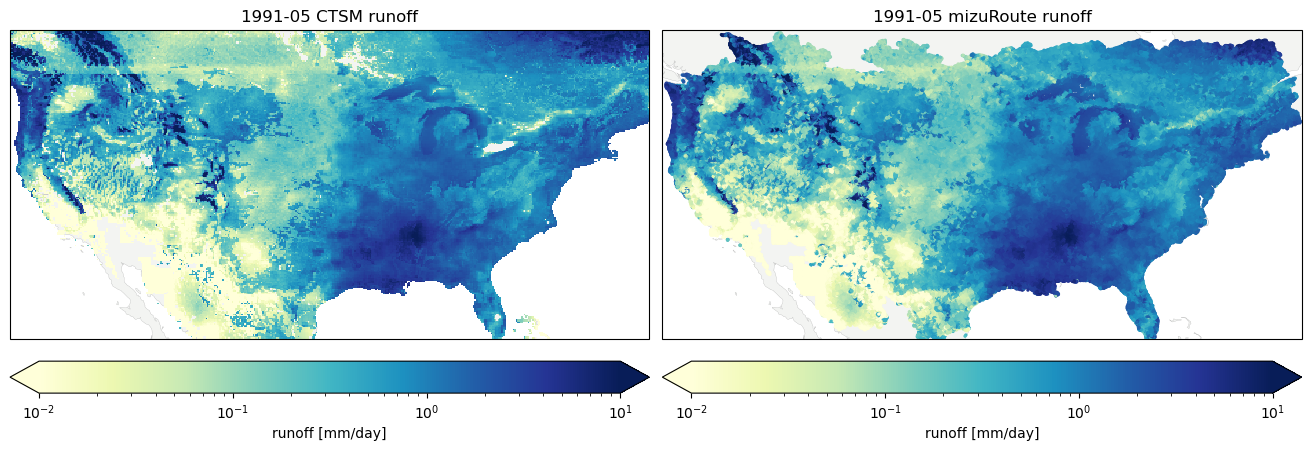

In [7]:
def plot_month(tindex, rof_var="RoutedRunoff", ctsm_var="QRUNOFF", savepath=False):
    fig, ax = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True,
                            subplot_kw={"projection": ccrs.PlateCarree()})

    ds_s = ds_ctsm.isel(time=tindex, drop=True).load()
    ds_r = ds_rof.isel(time=tindex, drop=True).load()
    datetime_str = ds_ctsm["time"].isel(time=tindex).values.item().strftime("%Y-%m")

    ax[0].add_feature(land, facecolor="xkcd:light gray", edgecolor="k", alpha=0.3, lw=0.2, zorder=0)
    field = (ds_s[ctsm_var] * var_meta[ctsm_var]["conversion"]).load()
    field.plot.pcolormesh(ax=ax[0], x="lon", y="lat", cmap="YlGnBu",
                           norm=var_meta[ctsm_var]["norm"], add_colorbar=True,
                           cbar_kwargs={"label": f"{var_meta[ctsm_var]['name']} [{var_meta[ctsm_var]['unit']}]", "orientation":"horizontal"})
    ax[0].set_title(f"{datetime_str} CTSM {var_meta[ctsm_var]['name']}")

    plot_lon, plot_lat = get_coords_for(rof_var)

    ax[1].add_feature(land, facecolor="xkcd:light gray", edgecolor="k", alpha=0.3, lw=0.2, zorder=0)
    values = (ds_r[rof_var] * var_meta[rof_var]["conversion"]).values
    sc = ax[1].scatter(plot_lon, plot_lat, c=values, s=2, cmap="YlGnBu",
                        norm=var_meta[rof_var]["norm"], transform=ccrs.PlateCarree())
    plt.colorbar(sc, ax=ax[1], label=f"{var_meta[rof_var]['name']} [{var_meta[rof_var]['unit']}]", orientation="horizontal",extend="both")
    ax[1].set_title(f"{datetime_str} mizuRoute {var_meta[rof_var]['name']}")

    extent = [235, 293, 25, 53]
    for a in ax:
        a.set_extent(extent, crs=ccrs.PlateCarree())
        a.set_aspect("equal")

    if savepath:
        fig.savefig(savepath, dpi=120, bbox_inches="tight")
    plt.show()
#    return fig

plot_month(12*10+7, rof_var="basRunoff", savepath=f"{OUT_DIR}/test_month0_basrunoff.png")
#plot_month(0, rof_var="RoutedRunoff", savepath=f"{OUT_DIR}/test_month0_routedrunoff.png")

## Animate across all months
Start with a shorter test range before committing to the full 456-month animation.

In [12]:
len(ds_ctsm['time'])

456

In [13]:
N_MONTHS_TEST = 24
# N_MONTHS_TEST = len(ds_ctsm['time'])

rof_var = "basRunoff"
ctsm_var = "QRUNOFF"

plot_lon, plot_lat = get_coords_for(rof_var)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True,
                        subplot_kw={"projection": ccrs.PlateCarree()})
extent = [235, 293, 25, 53]

for a in ax:
    a.add_feature(land, facecolor="xkcd:light gray", edgecolor="k", alpha=0.3, lw=0.2, zorder=0)
    a.set_extent(extent, crs=ccrs.PlateCarree())
    a.set_aspect("equal")

field0 = (ds_ctsm[ctsm_var].isel(time=0) * var_meta[ctsm_var]["conversion"]).load()
mesh0 = ax[0].pcolormesh(field0["lon"], field0["lat"], field0.values,
                          cmap="YlGnBu", norm=var_meta[ctsm_var]["norm"], transform=ccrs.PlateCarree())
plt.colorbar(mesh0, ax=ax[0], label=f"{var_meta[ctsm_var]['name']} [{var_meta[ctsm_var]['unit']}]")

values0 = (ds_rof[rof_var].isel(time=0) * var_meta[rof_var]["conversion"]).values
sc0 = ax[1].scatter(plot_lon, plot_lat, c=values0, s=3, cmap="YlGnBu",
                     norm=var_meta[rof_var]["norm"], transform=ccrs.PlateCarree())
plt.colorbar(sc0, ax=ax[1], label=f"{var_meta[rof_var]['name']} [{var_meta[rof_var]['unit']}]")

title0 = ax[0].set_title("")
title1 = ax[1].set_title("")

def update(tindex):
    datetime_str = ds_ctsm["time"].isel(time=tindex).values.item().strftime("%Y-%m")
    field = (ds_ctsm[ctsm_var].isel(time=tindex) * var_meta[ctsm_var]["conversion"]).load()
    mesh0.set_array(field.values.ravel())
    title0.set_text(f"{datetime_str} CTSM {var_meta[ctsm_var]['name']}")

    values = (ds_rof[rof_var].isel(time=tindex) * var_meta[rof_var]["conversion"]).values
    sc0.set_array(values)
    title1.set_text(f"{datetime_str} mizuRoute {var_meta[rof_var]['name']}")
    return mesh0, sc0, title0, title1

anim = FuncAnimation(fig, update, frames=N_MONTHS_TEST, blit=False)
anim.save(f"{OUT_DIR}/discharge_animation_{rof_var}.gif", writer="pillow", fps=2)
print(f"Saved animation to {OUT_DIR}/discharge_animation_{rof_var}.gif")
plt.close(fig)

Saved animation to discharge_maps/discharge_animation_basRunoff.gif
